# ConjunctivaGuard PoC, Part 2: load D01, find copies, make safe splits (module M1)

**What this part does**
1. Reads every D01 photo and its label (anemic or not) from the file name.
2. Finds copies of the same original photo (exact copies, renamed copies, rotated or flipped copies).
3. Puts all copies of one photo into one **photo group**.
4. Splits the **groups** (not the files) into train / validation / test (73 / 12 / 15%).
5. Checks there is **0 leakage**, and saves the result to your Google Drive.

Run the cells top to bottom with ▶.

### Cell 1: setup (run this every new session)
Connects Drive, downloads D01 again (Colab forgets everything when a session ends) and unpacks it. About 30 seconds.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, zipfile, glob, gdown

D01_LINK_ID = 'YOUR_D01_FILE_ID'     # your D01_Ghana.zip in Google Drive
OUT = '/content/drive/MyDrive/ConjunctivaGuard/poc_outputs'   # results are saved here (kept)
os.makedirs(OUT, exist_ok=True)

if not os.path.exists('/content/D01.zip'):
    gdown.download(id=D01_LINK_ID, output='/content/D01.zip', quiet=True)
if not os.path.exists('/content/work/D01'):
    with zipfile.ZipFile('/content/D01.zip') as zf:
        zf.extractall('/content/work/D01')

D01_DIR = glob.glob('/content/work/D01/*/')[0]
print('D01 photos:', len(os.listdir(D01_DIR)))
print('Results will be saved in:', OUT)

Mounted at /content/drive
D01 photos: 4262
Results will be saved in: /content/drive/MyDrive/ConjunctivaGuard/poc_outputs


### Cell 2: the tools (just run it)
This cell only **defines** small helper functions. Nothing visible happens. In plain words:

| Function | What it does |
|---|---|
| `base_name` | `Anemic-204 (6) - Copy.png` becomes `Anemic-204`, so the original photo's name is recovered |
| `label_from_name` | `Anemic…` gives 1 (anemic), `Non-anemic…` gives 0 |
| `file_md5` | a fingerprint of the file's bytes: two files with the same fingerprint are **exact copies** |
| `picture_hash` | a rough fingerprint of the picture's **outline**. It only *suggests* possible copies (many different eyelid strips have similar outlines) |
| `same_picture` | the strict check: turns picture B every way and measures the average colour difference with A (0 = identical). Joined only if the difference is **4 or less** (the limit) |
| `Groups` | joins files that belong together into one group |
| `split_groups` | shuffles the groups (fixed seed 42, so it gives the same result every time) and splits them 73 / 12 / 15% |
| `leakage_check` | counts anything that appears in more than one split (must be 0) |

In [ ]:
import os, re, glob, hashlib
import numpy as np
import pandas as pd
from PIL import Image

def base_name(filename):
    # 'Anemic-204 (6) - Copy.png' -> 'Anemic-204'
    name = os.path.splitext(filename)[0].strip()
    while True:
        new = re.sub(r'\s*-\s*Copy(-[A-Za-z0-9]{6})?$', '', name, flags=re.I)
        new = re.sub(r'\s*\(\d+\)(\s*-[A-Za-z0-9]{6})?$', '', new).strip()
        if new == name:
            return name
        name = new

def label_from_name(base):
    b = base.lower()
    if b.startswith('non'):
        return 0          # non-anemic
    if b.startswith('anemic'):
        return 1          # anemic
    return None

def file_md5(path):
    with open(path, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()

def picture_hash(path):
    # a small fingerprint of what the picture looks like;
    # the same for a photo and its rotated or flipped copies
    im = Image.open(path).convert('RGBA')
    bg = Image.new('RGBA', im.size, (255, 255, 255, 255))
    im = Image.alpha_composite(bg, im).convert('L')
    best = None
    for k in range(4):
        r = im.rotate(90 * k, expand=True)
        for v in (r, r.transpose(Image.FLIP_LEFT_RIGHT)):
            a = np.asarray(v.resize((9, 8), Image.BILINEAR), dtype=np.int16)
            bits = (a[:, 1:] > a[:, :-1]).flatten()
            h = int(''.join('1' if x else '0' for x in bits), 2)
            best = h if best is None else min(best, h)
    return format(best, '016x')

class Groups:
    # union-find: puts files that belong together into one group
    def __init__(self, n): self.p = list(range(n))
    def find(self, i):
        while self.p[i] != i:
            self.p[i] = self.p[self.p[i]]; i = self.p[i]
        return i
    def join(self, i, j): self.p[self.find(i)] = self.find(j)

def small_rgb(path, size=32):
    # the picture on a white background, shrunk to 32 x 32 colour pixels
    im = Image.open(path).convert('RGBA')
    bg = Image.new('RGBA', im.size, (255, 255, 255, 255))
    im = Image.alpha_composite(bg, im).convert('RGB')
    return im, np.asarray(im.resize((size, size), Image.BILINEAR), dtype=np.float32)

def same_picture(path_a, path_b, max_diff=4.0):
    # True only if B is A, maybe rotated or flipped, with (almost) identical pixels
    ima, a = small_rgb(path_a)
    imb, _ = small_rgb(path_b)
    ra = ima.size[0] / ima.size[1]
    best = 999.0
    for k in range(4):
        r = imb.rotate(90 * k, expand=True)
        for v in (r, r.transpose(Image.FLIP_LEFT_RIGHT)):
            rb = v.size[0] / v.size[1]
            if abs(rb - ra) / ra > 0.05:          # different shape of box: not the same
                continue
            b = np.asarray(v.resize((32, 32), Image.BILINEAR), dtype=np.float32)
            best = min(best, float(np.abs(a - b).mean()))
    return best <= max_diff, best

def build_table(folder, manual_join=()):
    files = sorted(f for f in os.listdir(folder) if f.lower().endswith('.png'))
    df = pd.DataFrame({'file': files})
    df['path'] = [os.path.join(folder, f) for f in files]
    df['base'] = df['file'].map(base_name)
    df['label'] = df['base'].map(label_from_name)
    df['md5'] = df['path'].map(file_md5)
    df['phash'] = df['path'].map(picture_hash)
    g = Groups(len(df))
    # 1) same original name, 2) exact byte copies
    for col in ('base', 'md5'):
        for _, idx in df.groupby(col).groups.items():
            idx = list(idx)
            for j in idx[1:]:
                g.join(idx[0], j)
    # 3) look-alike copies under another name: the outline fingerprint only
    #    suggests candidates; colours must also match (same_picture)
    uniq = df.drop_duplicates('md5')
    checked = []
    for _, idx in uniq.groupby('phash').groups.items():
        idx = list(idx)
        for a in range(len(idx)):
            for b in range(a + 1, len(idx)):
                i, j = idx[a], idx[b]
                if g.find(i) == g.find(j):
                    continue
                ok, d = same_picture(df.at[i, 'path'], df.at[j, 'path'])
                checked.append((df.at[i, 'file'], df.at[j, 'file'], round(d, 1), ok))
                if ok:
                    g.join(i, j)
    build_table.checked = pd.DataFrame(checked, columns=['file_a', 'file_b', 'colour_diff', 'joined'])
    # 4) manual decisions: borderline pairs checked by eye
    pos = {f: i for i, f in enumerate(df['file'])}
    for a, b, reason in manual_join:
        if a not in pos or b not in pos:
            raise ValueError(f'Manual decision: file not found: {a} or {b}')
        g.join(pos[a], pos[b])
    roots = [g.find(i) for i in range(len(df))]
    ids = {r: k for k, r in enumerate(sorted(set(roots)))}
    df['group'] = [f'G{ids[r]:04d}' for r in roots]
    return df

def split_groups(df, seed=42, val=0.12, test=0.15):
    lab = df.groupby('group')['label'].agg(lambda s: set(s))
    mixed = lab[lab.map(len) > 1].index
    clean = lab[lab.map(len) == 1].map(lambda s: next(iter(s)))
    rng = np.random.default_rng(seed)
    split = {}
    for y in (0, 1):
        gs = sorted(clean[clean == y].index)
        rng.shuffle(gs)
        n_test = round(test * len(gs)); n_val = round(val * len(gs))
        for k, gid in enumerate(gs):
            split[gid] = 'test' if k < n_test else ('val' if k < n_test + n_val else 'train')
    for gid in mixed:
        split[gid] = 'excluded'
    df = df.copy()
    df['split'] = df['group'].map(split)
    # remove exact byte copies (keep the first)
    df['keep'] = ~df.duplicated('md5')
    # val/test: one picture per group, so a photo is not scored many times
    first = ~df[df['keep']].duplicated('group')
    df['eval_image'] = False
    df.loc[first[first].index, 'eval_image'] = True
    return df, list(mixed)

def leakage_check(df):
    d = df[df['split'].isin(['train', 'val', 'test'])]
    res = {}
    for col in ('group', 'md5'):
        sets = {s: set(d.loc[d['split'] == s, col]) for s in ('train', 'val', 'test')}
        res[col] = len(sets['train'] & sets['val']) + len(sets['train'] & sets['test']) + len(sets['val'] & sets['test'])
    # verified look-alike copies (rotated / flipped, identical pixels) in different splits
    split_of = dict(zip(df['file'], df['split']))
    chk = getattr(build_table, 'checked', None)
    n = 0
    if chk is not None and len(chk):
        for _, r in chk[chk['joined']].iterrows():
            a, b = split_of.get(r['file_a']), split_of.get(r['file_b'])
            if a != b and a != 'excluded' and b != 'excluded':
                n += 1
    res['same picture'] = n
    return res


### Cell 2b: my manual decisions (audit trail)
The automatic limit (4) handles the clear cases. Borderline pairs were **checked by eye** (18 Nov 2026) and the decisions are written here with a reason. This list is the **audit trail**: written proof of what was decided and why.

Rule for unsure cases: **join** (the safe choice). Joining two different photos only loses a little variety; keeping one eyelid apart could cause leakage.

In [ ]:
MANUAL_JOIN = [
    # (file A, file B, reason)
    ('Non-Anemic-083.png', 'Non-Anemic-122.png',
     'score 7.5; same outline, different colour; unsure, joined to be safe'),
]

REVIEWED = [   # every borderline pair looked at by eye, and the verdict
    ('Anemic-039 (2).png', 'Anemic-130.png',     2.4, 'same eyelid, lower-quality copy',            'join (by limit 4)'),
    ('Anemic-016 (2).png', 'Anemic-020 (2).png', 2.4, 'same eyelid, flipped, slightly different cut', 'join (by limit 4)'),
    ('Non-Anemic-083.png', 'Non-Anemic-122.png', 7.5, 'same outline, different colour: unsure',     'join (manual, safe choice)'),
    ('Anemic-173.png',     'Non-Anemic-109.png', 7.7, 'different colour, texture and cut',          'keep apart'),
]
print('Manual joins:', len(MANUAL_JOIN), '| pairs reviewed by eye:', len(REVIEWED))

Manual joins: 1 | pairs reviewed by eye: 4


### Cell 3: read all photos and build the groups
**Lesson: why groups?** The dataset was made bigger (augmented) by copying each original photo several times: `Anemic-001 (10).png`, `Anemic-001 (11).png`… If one copy is in *train* and another in *test*, the model has already seen the exam answer. So we split by **photo group**, never by single file. About 1 minute.

In [ ]:
df = build_table(D01_DIR, manual_join=MANUAL_JOIN)

print('Files (all photos)         :', len(df))
print('Anemic / non-anemic files  :', int((df.label == 1).sum()), '/', int((df.label == 0).sum()))
print('Unknown label              :', int(df.label.isna().sum()))
print('Original names (base)      :', df.base.nunique())
print('Byte-unique files          :', df.md5.nunique())
print('Photo groups               :', df.group.nunique())
print()
print('Your slides said: 4,262 files | 2,015 byte-unique | about 404 photo groups (older, looser check)')
chk = build_table.checked
print(f'\nLook-alike pairs checked: {len(chk)} | really the same picture (joined): {int(chk.joined.sum())}')

big = df.groupby('group').base.nunique().sort_values(ascending=False)
print('\nLargest groups (how many different names were joined):')
print(big.head(5).to_string())

Files (all photos)         : 4262
Anemic / non-anemic files  : 2558 / 1704
Unknown label              : 0
Original names (base)      : 527
Byte-unique files          : 2015
Photo groups               : 503

Your slides said: 4,262 files | 2,015 byte-unique | about 404 photo groups (older, looser check)

Look-alike pairs checked: 1998 | really the same picture (joined): 18

Largest groups (how many different names were joined):
group
G0278    7
G0282    5
G0000    4
G0281    4
G0036    2


### Cell 3b: the borderline pairs you checked by eye
Each row shows one reviewed pair and your verdict. Rows 1 and 2 are joined by the limit; row 3 is joined by your manual decision; row 4 stays apart, so there is **no label conflict** (it had opposite labels).

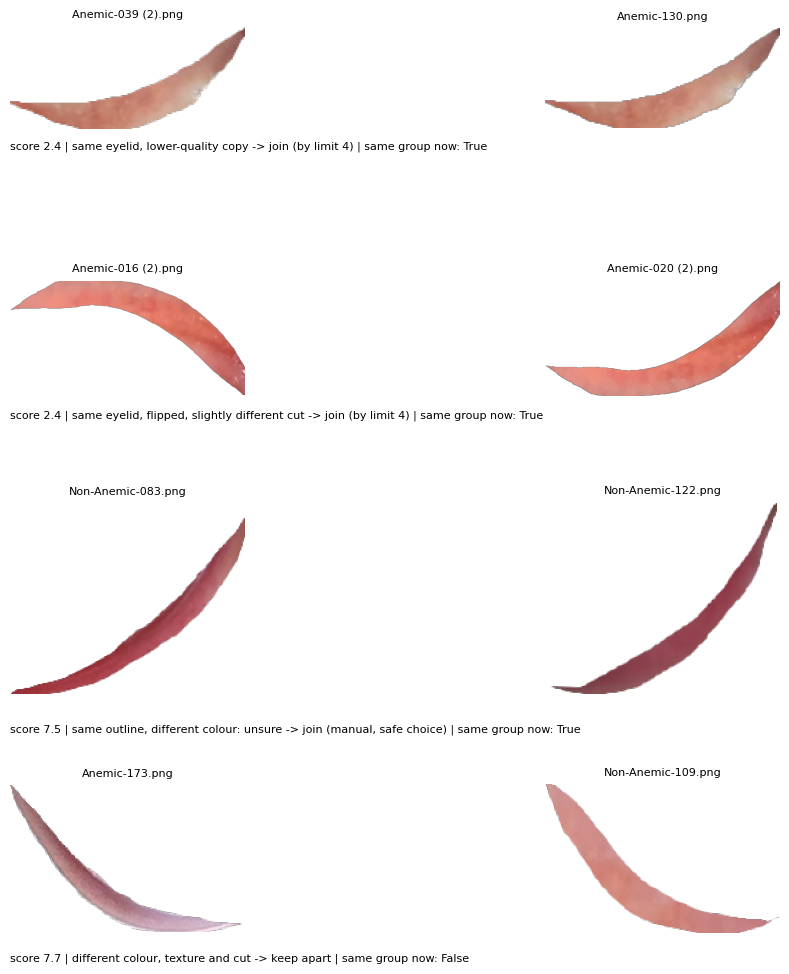

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

fig, axes = plt.subplots(len(REVIEWED), 2, figsize=(8, 2.6 * len(REVIEWED)))
for row, (a, b, score, why, action) in zip(axes, REVIEWED):
    for ax, f in zip(row, (a, b)):
        ax.imshow(Image.open(os.path.join(D01_DIR, f))); ax.set_title(f, fontsize=8); ax.axis('off')
    same = df.loc[df.file == a, 'group'].iloc[0] == df.loc[df.file == b, 'group'].iloc[0]
    row[0].text(0, -0.2, f'score {score} | {why} -> {action} | same group now: {same}',
                transform=row[0].transAxes, fontsize=8)
plt.tight_layout(); plt.show()

### Cell 4: see one photo group
These are all files of **one** original photo. Some are exact copies, some rotated or flipped. They must all go to the same split.

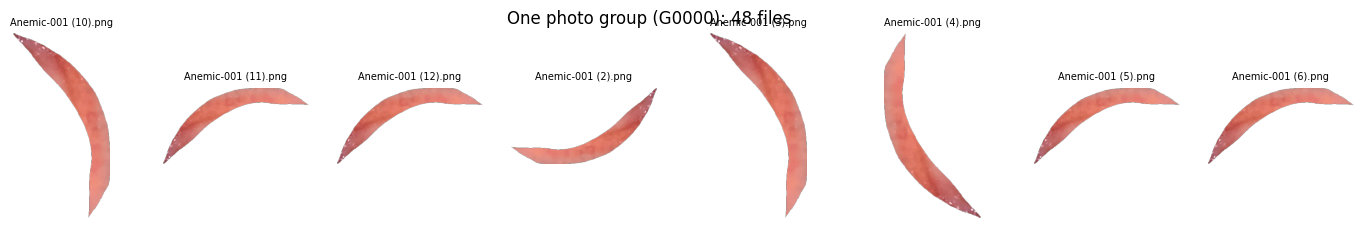

In [ ]:
g = df.group.value_counts().index[0]          # the group with the most files
items = df[df.group == g].head(8)
fig, axes = plt.subplots(1, len(items), figsize=(2.2 * len(items), 2.4))
for ax, (_, r) in zip(axes, items.iterrows()):
    ax.imshow(Image.open(r.path)); ax.set_title(r.file[:20], fontsize=7); ax.axis('off')
plt.suptitle(f'One photo group ({g}): {len(df[df.group == g])} files'); plt.show()

### Cell 5: make the splits
**Lesson:** groups that contain **both** anemic and non-anemic labels are a contradiction (the same eyelid cannot be both), so they are **excluded**. Your slides call these "cross-label near-duplicates". With the strict check we expect **0**.

Inside each split we also remove exact byte copies. For validation and test we keep **one picture per group**, so a single photo is not scored many times.

In [ ]:
df, mixed = split_groups(df, seed=42)

print('Groups with conflicting labels (excluded):', len(mixed))
summary = (df[df.split != 'excluded']
           .groupby('split')
           .agg(groups=('group', 'nunique'),
                files_kept=('keep', 'sum'),
                eval_images=('eval_image', 'sum'),
                anemic_share=('label', 'mean'))
           .reindex(['train', 'val', 'test']))
summary['group_%'] = (100 * summary.groups / summary.groups.sum()).round(1)
summary['anemic_share'] = summary.anemic_share.round(2)
display(summary)

Groups with conflicting labels (excluded): 0


,groups,files_kept,eval_images,anemic_share,group_%
split,,,,,
train,368,1467,368,0.60,73.2
val,60,239,60,0.61,11.9
test,75,309,75,0.60,14.9


### Cell 6: leakage check
**Lesson:** this is the most important check of Part 2. It counts photo groups, exact copies and verified same pictures (rotated or flipped copies) that appear in more than one split. **All three must be 0.** (This is test TD1 and requirement NFR02 in your proposal.)

In [ ]:
res = leakage_check(df)
for k, v in res.items():
    print(f'{k:12s} shared between splits: {v}', '✅' if v == 0 else '❌')
print('\nRESULT:', '0 shared groups, no leakage ✅' if sum(res.values()) == 0 else 'LEAKAGE FOUND ❌')

group        shared between splits: 0 ✅
md5          shared between splits: 0 ✅
same picture shared between splits: 0 ✅

RESULT: 0 shared groups, no leakage ✅


### Cell 7: save the result to Google Drive
Saves the table (every file with its label, group and split) as `D01_splits.csv` in `ConjunctivaGuard/poc_outputs`. Later parts **read this file**, so the split never changes.

In [ ]:
cols = ['file', 'base', 'label', 'group', 'split', 'keep', 'eval_image', 'md5', 'phash']
df[cols].to_csv(os.path.join(OUT, 'D01_splits.csv'), index=False)
old = os.path.join(OUT, 'D01_excluded_conflicts.csv')
if os.path.exists(old):
    os.remove(old)                      # remove the wrong list from version 1
if mixed:
    df[df.group.isin(mixed)][['file', 'label', 'group']].to_csv(old, index=False)
build_table.checked.to_csv(os.path.join(OUT, 'D01_lookalike_checks.csv'), index=False)
pd.DataFrame(REVIEWED, columns=['file_a', 'file_b', 'score', 'verdict', 'action']).to_csv(
    os.path.join(OUT, 'D01_manual_decisions.csv'), index=False)
print('Saved:', os.listdir(OUT))

Saved: ['D01_lookalike_checks.csv', 'D01_splits.csv', 'D01_manual_decisions.csv']


### Part 2 done ✅
**Outputs to check:** the outputs of **Cell 3, Cell 5 and Cell 6** (text). Expected: about **503 photo groups**, **0 conflicts**, **0 leakage**.

**What you learned**
- **Augmentation** = making more training images by copying, rotating and flipping. Useful for training, dangerous for testing.
- **Photo group** = all copies of one original photo. We split groups, never single files.
- **Leakage** = the same photo in train and test. The check must say 0.
- **Threshold (limit)** = the line between "same" and "different". Put it in the empty gap between the clusters of scores (here 4).
- **Audit trail** = a written list of borderline decisions with reasons, so anyone can check your choices.
- **Check your checker**: the first version's look-alike test was too loose and joined different children's photos. Looking at the pictures showed the mistake.
- **Seed** = a fixed number (42) that makes the "random" shuffle give the same result every time, so anyone can repeat it.